# 03 — Derivatives, gradients, and Jacobians

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–02: tensors, dtypes, dot products, matrix–vector products |
| **You will learn** | What a derivative measures; finite differences and their errors; the derivative rules, including the chain rule; partial derivatives, gradients, and directional derivatives; gradient descent and why it can oscillate or diverge; Jacobians, the chain rule as a product of Jacobians, and vector–Jacobian products |
| **Estimated time** | 3 hours |
| **Compute** | CPU only, under a minute. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import math
import time

from dlcourse.plotting import COLORS

f64 = torch.float64  # numerical checks in this notebook use 64-bit floats on the CPU (MPS has no float64)

Everything in this notebook runs on the CPU. We compute every derivative **by hand** and check it with arithmetic; PyTorch's automatic differentiation comes in notebook 05, and you will understand what it does because you will have done it yourself here.

## Motivating problem

Training a neural network means adjusting its **parameters** — often millions of numbers — so that a **loss** $L$, a single number measuring how wrong the network's predictions are, gets smaller.

Suppose you could compute $L$ for any setting of the parameters. Two questions remain:

1. **Which direction** should each parameter move to make $L$ smaller?
2. **How far** should it move?

Trying random changes is hopeless with a million parameters. This notebook builds the tool that answers both questions — the **gradient** — and shows what goes wrong when the step size is chosen badly.

## 1. The derivative: slope as a rate of change

For a function of one number, $f(x)$, the **derivative** $f'(x)$ answers: *if I nudge $x$ a little, how fast does $f$ change?*

Pick a small step $h$ and look at the slope of the straight line through the points $(x, f(x))$ and $(x+h, f(x+h))$, called a **secant**:

$$\text{secant slope} = \frac{f(x+h) - f(x)}{h}.$$

As $h$ shrinks, the secant pivots toward the **tangent line**, the line that just touches the curve at $x$. The derivative is the limit of the secant slope:

$$f'(x) = \lim_{h \to 0} \frac{f(x+h) - f(x)}{h}.$$

We also write $\frac{df}{dx}$ for $f'(x)$.

**A worked example.** Take $f(x) = x^3 - 2x + 1$ at $x = 1$, where $f(1) = 0$. Expand $(1+h)^3 = 1 + 3h + 3h^2 + h^3$:

$$\frac{f(1+h) - f(1)}{h} = \frac{(1 + 3h + 3h^2 + h^3) - 2(1+h) + 1 - 0}{h} = \frac{h + 3h^2 + h^3}{h} = 1 + 3h + h^2.$$

As $h \to 0$ the extra terms vanish, so $f'(1) = 1$. Let's check the formula $1 + 3h + h^2$ against direct arithmetic.

In [3]:
def f_cubic(x):
    return x**3 - 2 * x + 1


x0 = 1.0
for h in [1.0, 0.5, 0.1, 0.01, 0.001]:
    secant = (f_cubic(x0 + h) - f_cubic(x0)) / h
    print(f"h = {h:<6}  secant slope = {secant:.6f}   formula 1 + 3h + h² = {1 + 3 * h + h**2:.6f}")

h = 1.0     secant slope = 5.000000   formula 1 + 3h + h² = 5.000000
h = 0.5     secant slope = 2.750000   formula 1 + 3h + h² = 2.750000
h = 0.1     secant slope = 1.310000   formula 1 + 3h + h² = 1.310000
h = 0.01    secant slope = 1.030100   formula 1 + 3h + h² = 1.030100
h = 0.001   secant slope = 1.003001   formula 1 + 3h + h² = 1.003001


The slopes approach 1, and the error shrinks roughly in proportion to $h$ (the $3h$ term dominates for small $h$). Now the picture:

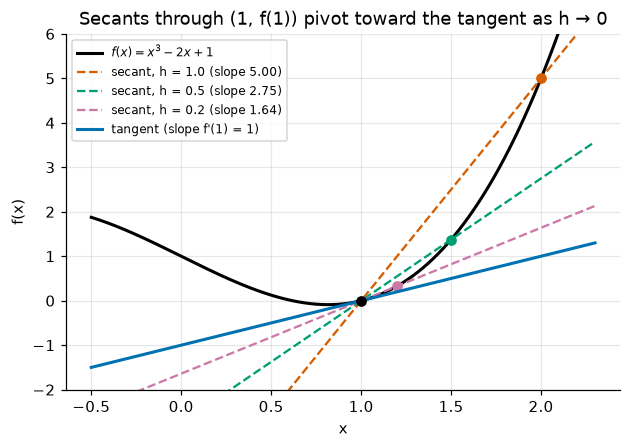

In [4]:
xs = torch.linspace(-0.5, 2.3, 200)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(xs, f_cubic(xs), color="black", lw=2, label="$f(x) = x^3 - 2x + 1$")
for h, color in zip([1.0, 0.5, 0.2], COLORS[1:4]):
    slope = (f_cubic(x0 + h) - f_cubic(x0)) / h
    ax.plot(xs, f_cubic(x0) + slope * (xs - x0), "--", color=color, label=f"secant, h = {h} (slope {slope:.2f})")
    ax.plot([x0 + h], [f_cubic(x0 + h)], "o", color=color)
ax.plot(xs, f_cubic(x0) + 1.0 * (xs - x0), color=COLORS[0], lw=2, label="tangent (slope f'(1) = 1)")
ax.plot([x0], [f_cubic(x0)], "ko")
ax.set_ylim(-2, 6)
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_title("Secants through (1, f(1)) pivot toward the tangent as h → 0")
ax.legend(fontsize=8, loc="upper left")
plt.show()

Each secant passes through the black point and one colored point. As the colored point slides toward $x = 1$, the secant's slope (5.00, 2.75, 1.64) falls toward the tangent's slope, 1.

**Where the picture stops being accurate:** a derivative is a property of the function at one point, but the plot can only show finitely many secants. A function can also have no tangent at all at a point — a sharp corner, which we meet with ReLU in Section 3.

## 2. Finite differences: computing derivatives numerically

The secant slope with a small, fixed $h$ is a **finite-difference** approximation of the derivative. It needs only the ability to *evaluate* $f$, so it is a universal way to check a derivative computed by hand. But how small should $h$ be? Smaller is not always better on a computer.

Two formulas:

- **Forward difference:** $\displaystyle D_h^{+} f(x) = \frac{f(x+h) - f(x)}{h}$
- **Central difference:** $\displaystyle D_h^{c} f(x) = \frac{f(x+h) - f(x-h)}{2h}$ — the slope of the secant through two points placed symmetrically around $x$.

### Truncation error

To see how accurate each formula is, we use **Taylor's theorem** (stated without proof): for a smooth $f$ and small $h$,

$$f(x+h) = f(x) + h f'(x) + \tfrac{h^2}{2} f''(x) + \tfrac{h^3}{6} f'''(x) + \dots$$

where $f''$ is the derivative of $f'$ (the **second derivative**, which measures curvature) and $f'''$ the third.

- Forward: subtract $f(x)$ and divide by $h$: $D_h^{+} f(x) = f'(x) + \tfrac{h}{2} f''(x) + \dots$ The error is proportional to $h$, written $O(h)$.
- Central: write the expansion for $f(x-h)$ too (replace $h$ by $-h$). Subtracting, the even terms cancel: $f(x+h) - f(x-h) = 2h f'(x) + \tfrac{h^3}{3} f'''(x) + \dots$, so $D_h^{c} f(x) = f'(x) + \tfrac{h^2}{6} f'''(x) + \dots$ The error is $O(h^2)$.

This error, from cutting the Taylor series short, is the **truncation error**. Shrinking $h$ by $10\times$ should shrink the forward error by about $10\times$ and the central error by about $100\times$. We test this on $f(x) = e^x$ at $x = 1$, where every derivative equals $e$.

In [5]:
x = torch.tensor(1.0, dtype=f64)
true_slope = math.e
print(f"{'h':>6} | {'forward error':>14} {'predicted h·e/2':>16} | {'central error':>14} {'predicted h²·e/6':>17}")
for h in [1e-1, 1e-2, 1e-3]:
    fwd = (torch.exp(x + h) - torch.exp(x)) / h
    cen = (torch.exp(x + h) - torch.exp(x - h)) / (2 * h)
    print(f"{h:>6} | {abs(fwd.item() - true_slope):>14.3e} {h * math.e / 2:>16.3e} | "
          f"{abs(cen.item() - true_slope):>14.3e} {h**2 * math.e / 6:>17.3e}")

     h |  forward error  predicted h·e/2 |  central error  predicted h²·e/6
   0.1 |      1.406e-01        1.359e-01 |      4.533e-03         4.530e-03
  0.01 |      1.364e-02        1.359e-02 |      4.530e-05         4.530e-05
 0.001 |      1.360e-03        1.359e-03 |      4.530e-07         4.530e-07


The measured errors match the leading Taylor terms: each tenfold reduction of $h$ divides the forward error by about 10 and the central error by about 100. The central difference costs the same two function evaluations as the forward difference but is far more accurate.

### Checkpoint 2.1

Write `central_difference(f, x, h)` that returns $\frac{f(x+h) - f(x-h)}{2h}$. Before running the check, compute by hand what it should return for $f(x) = x^3$ at $x = 1$ with $h = 0.1$.

<details>
<summary><b>💡 Hint</b></summary>

By hand: $(1.1^3 - 0.9^3)/0.2 = (1.331 - 0.729)/0.2 = 3.01$. The exact derivative is 3, and the error $h^2 f'''/6 = 0.01 \cdot 6/6 = 0.01$ matches. The function itself is one line.

</details>

In [ ]:
def central_difference(f, x, h):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
estimate = central_difference(lambda t: t**3, torch.tensor(1.0, dtype=f64), 0.1)
check_close(estimate, 3.01, "central_difference(x³, 1, 0.1)", rtol=1e-12, atol=1e-12)
check_close(central_difference(torch.sin, torch.tensor(0.7, dtype=f64), 1e-5), math.cos(0.7),
            "central_difference(sin, 0.7, 1e-5)", rtol=1e-9, atol=1e-9)
passed("Checkpoint 2.1")

From here on, teaching cells use this reference version, which works elementwise on tensors:

In [8]:
def derivative(f, x, h=1e-6):
    """Central-difference estimate of f'(x). Use float64 inputs."""
    return (f(x + h) - f(x - h)) / (2 * h)

### Rounding error: why tiny $h$ fails

A computer stores $f(x+h)$ and $f(x)$ with a relative rounding error of about $\varepsilon$, the **machine epsilon** — the gap between 1 and the next representable number. For small $h$ the two values are nearly equal, so their difference loses most of its significant digits, and dividing by $h$ magnifies what is left. The rounding error of the difference quotient is roughly $\varepsilon |f(x)| / h$: it **grows** as $h$ shrinks. (This is an order-of-magnitude model, not an exact formula.)

The total error is therefore roughly

$$\text{error}(h) \approx \underbrace{C h^p}_{\text{truncation}} + \underbrace{\frac{\varepsilon |f(x)|}{h}}_{\text{rounding}},$$

with $p = 1$ (forward) or $p = 2$ (central). Setting the derivative of this with respect to $h$ to zero gives the best step size. For $e^x$ at $x=1$, where $f = f'' = f''' = e$:

- forward, $C = e/2$: $\;h^{*} = \sqrt{2\varepsilon}$
- central, $C = e/6$: $\;h^{*} = (3\varepsilon)^{1/3}$

In [9]:
for dtype in (torch.float32, torch.float64):
    eps = torch.finfo(dtype).eps
    print(f"{str(dtype):>14}: eps = {eps:.2e}   predicted best h: forward {math.sqrt(2 * eps):.1e}, "
          f"central {(3 * eps) ** (1 / 3):.1e}")

 torch.float32: eps = 1.19e-07   predicted best h: forward 4.9e-04, central 7.1e-03
 torch.float64: eps = 2.22e-16   predicted best h: forward 2.1e-08, central 8.7e-06


Now measure the error over 15 orders of magnitude of $h$, in both precisions. The true derivative is $e$; the "error" is the absolute difference from it.

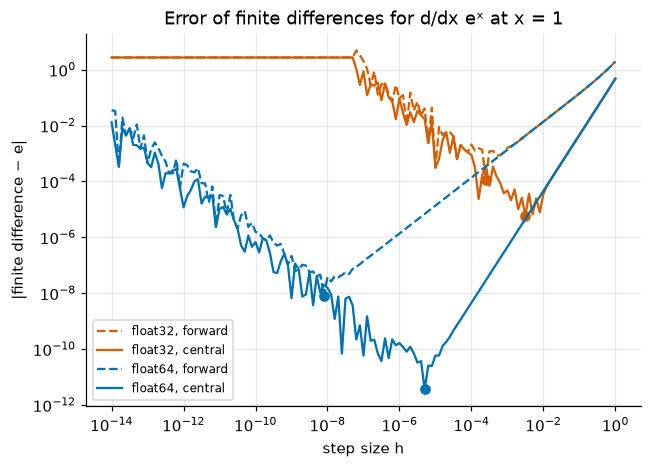

   dtype   method |   best h best error | error at h = 1e-12
 float32  forward |  2.5e-04    1.2e-04 |            2.7e+00
 float32  central |  3.2e-03    5.8e-06 |            2.7e+00
 float64  forward |  7.9e-09    7.7e-09 |            4.3e-04
 float64  central |  5.0e-06    3.6e-12 |            1.2e-05
exactly-zero errors (not drawable on log axes): 0
float32: 1 + 5e-8 == 1 ? True   1 + 7e-8 == 1 ? False


In [10]:
hs = torch.logspace(-14, 0, 141, dtype=f64)  # step sizes from 1e-14 to 1
errors = {}
for dtype in (torch.float32, torch.float64):
    x = torch.tensor(1.0, dtype=dtype)
    h = hs.to(dtype)
    fwd = (torch.exp(x + h) - torch.exp(x)) / h
    cen = (torch.exp(x + h) - torch.exp(x - h)) / (2 * h)
    errors[(dtype, "forward")] = (fwd.to(f64) - math.e).abs()
    errors[(dtype, "central")] = (cen.to(f64) - math.e).abs()

fig, ax = plt.subplots(figsize=(6.5, 4.4))
styles = {(torch.float32, "forward"): (COLORS[1], "--"), (torch.float32, "central"): (COLORS[1], "-"),
          (torch.float64, "forward"): (COLORS[0], "--"), (torch.float64, "central"): (COLORS[0], "-")}
for key, err in errors.items():
    dtype, method = key
    color, ls = styles[key]
    shown = err.clamp_min(1e-17)  # an error of exactly 0 cannot be drawn on a log axis
    ax.loglog(hs, shown, ls, color=color, label=f"{str(dtype).replace('torch.', '')}, {method}")
    best = int(err.argmin())
    ax.plot(hs[best], shown[best], "o", color=color)
ax.set_xlabel("step size h")
ax.set_ylabel("|finite difference − e|")
ax.set_title("Error of finite differences for d/dx eˣ at x = 1")
ax.legend(fontsize=8)
plt.show()

print(f"{'dtype':>8} {'method':>8} | {'best h':>8} {'best error':>10} | {'error at h = 1e-12':>18}")
for (dtype, method), err in errors.items():
    best = int(err.argmin())
    at_tiny = err[int((hs - 1e-12).abs().argmin())].item()
    print(f"{str(dtype).replace('torch.', ''):>8} {method:>8} | {hs[best].item():>8.1e} {err[best].item():>10.1e} | {at_tiny:>18.1e}")
print("exactly-zero errors (not drawable on log axes):", sum(int((e == 0).sum()) for e in errors.values()))
one32 = torch.tensor(1.0, dtype=torch.float32)
print("float32: 1 + 5e-8 == 1 ?", bool(one32 + 5e-8 == one32), "  1 + 7e-8 == 1 ?", bool(one32 + 7e-8 == one32))

Each curve is a **V**. On the right, truncation error dominates: the dashed forward curves fall with slope 1 on the log–log plot (error $\propto h$), the solid central curves with slope 2 (error $\propto h^2$). Where truncation dominates, the `float32` and `float64` curves lie on top of each other: precision does not matter there. On the left, rounding error dominates and grows like $1/h$, jagged because rounding is erratic. In `float32`, for $h$ below about $6 \times 10^{-8}$ (half of $\varepsilon$) the sum $1 + h$ rounds to exactly $1$ (checked in the last printed line), the two function values are identical, and the estimate is $0$ — an error equal to the whole derivative, $e$. The best step sizes (dots) land within a factor of about 3 of the predictions above — the right order of magnitude, which is all the rough rounding model promises.

Two consequences:

- The **best achievable** accuracy is limited: about $10^{-12}$ in `float64` but only about $10^{-5}$ in `float32` with a central difference (and far worse with a forward difference). Always run finite-difference checks in `float64`.
- A finite-difference gradient for a model with $n$ parameters needs $2n$ evaluations of the loss — two million full passes over the data for a modest million-parameter model, for **one** step. Finite differences are a **check** for derivatives computed some other way, never a way to train.

## 3. Rules for computing derivatives exactly

Taking limits every time is tedious. A handful of rules, each derived from the limit definition, let us differentiate any formula built from simple pieces. Throughout, $f$ and $g$ are functions of $x$ and $c$ is a constant.

**Power rule:** $\frac{d}{dx} x^n = n x^{n-1}$. For $n = 2$: $\frac{(x+h)^2 - x^2}{h} = \frac{2xh + h^2}{h} = 2x + h \to 2x$. For any positive integer $n$ the same expansion works (the binomial theorem gives $(x+h)^n = x^n + n x^{n-1} h + (\text{terms with } h^2)$); for other real $n$ we state the rule without proof.

**Constant multiple and sum rules:** $(c f)' = c f'$ and $(f + g)' = f' + g'$. The difference quotient of a sum is the sum of the difference quotients, and limits add.

**Product rule:** $(fg)' = f'g + fg'$. Add and subtract $f(x+h)g(x)$ in the numerator:

$$\frac{f(x+h)g(x+h) - f(x)g(x)}{h} = f(x+h)\frac{g(x+h) - g(x)}{h} + g(x)\frac{f(x+h) - f(x)}{h} \;\to\; f(x)g'(x) + g(x)f'(x).$$

**Chain rule:** for a composition $f(g(x))$ — first apply $g$, then $f$ —

$$\frac{d}{dx} f(g(x)) = f'(g(x))\, g'(x).$$

Why: a small step $h$ in $x$ changes $g$ by about $g'(x) h$. A change of $\delta$ in the input of $f$ changes $f$ by about $f'(g(x)) \delta$. So the total change is about $f'(g(x))\, g'(x)\, h$. **Rates of change multiply along a chain.** (This argument uses "about" twice; a careful proof controls those approximation errors, and we state the rule without it.)

The chain rule is the single most important rule in deep learning: a network is a long chain of simple functions, and Sections 7–8 extend this rule to whole vectors.

### Exponential, logarithm, and two activation functions

- $\frac{d}{dx} e^x = e^x$ (stated; it is the defining property of $e$). Section 2 already checked it numerically at $x = 1$.
- $\frac{d}{dx} \ln x = \frac{1}{x}$ for $x > 0$. Derivation: differentiate both sides of $e^{\ln x} = x$ with the chain rule: $e^{\ln x} \cdot (\ln x)' = 1$, so $(\ln x)' = 1 / e^{\ln x} = 1/x$.
- **Sigmoid**, $\sigma(x) = \dfrac{1}{1 + e^{-x}}$, squashes any number into $(0, 1)$. With the chain rule (outer function $u^{-1}$, inner $u = 1 + e^{-x}$): $\sigma'(x) = -\dfrac{1}{(1+e^{-x})^2} \cdot (-e^{-x}) = \dfrac{e^{-x}}{(1+e^{-x})^2}$. Since $1 - \sigma(x) = \dfrac{e^{-x}}{1+e^{-x}}$, this is
$$\sigma'(x) = \sigma(x)\,\big(1 - \sigma(x)\big).$$
- **Hyperbolic tangent**, $\tanh(x) = \dfrac{e^x - e^{-x}}{e^x + e^{-x}}$, squashes into $(-1, 1)$. One can check algebraically that $\tanh(x) = 2\sigma(2x) - 1$. The chain rule then gives $\tanh'(x) = 4\,\sigma(2x)(1 - \sigma(2x))$, and substituting $\sigma(2x) = (1 + \tanh x)/2$ simplifies this to
$$\tanh'(x) = 1 - \tanh^2(x).$$

Both derivatives are expressed through the function's own output — a convenience autograd exploits (notebook 05).

Every rule above, checked numerically at $x = 0.8$ against the central difference:

In [11]:
x = torch.tensor(0.8, dtype=f64)
rules = [
    ("power      x^5",           lambda t: t**5,                  lambda t: 5 * t**4),
    ("sum        x^3 + e^x",     lambda t: t**3 + torch.exp(t),   lambda t: 3 * t**2 + torch.exp(t)),
    ("product    x^2 sin x",     lambda t: t**2 * torch.sin(t),   lambda t: 2 * t * torch.sin(t) + t**2 * torch.cos(t)),
    ("chain      sin(x^2)",      lambda t: torch.sin(t**2),       lambda t: torch.cos(t**2) * 2 * t),
    ("exp        e^x",           torch.exp,                       torch.exp),
    ("log        ln x",          torch.log,                       lambda t: 1 / t),
    ("sigmoid    σ(x)",          torch.sigmoid,                   lambda t: torch.sigmoid(t) * (1 - torch.sigmoid(t))),
    ("tanh       tanh x",        torch.tanh,                      lambda t: 1 - torch.tanh(t) ** 2),
]
for name, f, df in rules:
    analytic, numeric = df(x).item(), derivative(f, x).item()
    print(f"{name:<24} analytic {analytic:+.10f}   central diff {numeric:+.10f}   |diff| {abs(analytic - numeric):.1e}")

power      x^5           analytic +2.0480000000   central diff +2.0480000001   |diff| 6.0e-11
sum        x^3 + e^x     analytic +4.1455409285   central diff +4.1455409288   |diff| 2.6e-10
product    x^2 sin x     analytic +1.5936620394   central diff +1.5936620395   |diff| 5.2e-11
chain      sin(x^2)      analytic +1.2833532126   central diff +1.2833532126   |diff| 3.0e-11
exp        e^x           analytic +2.2255409285   central diff +2.2255409287   |diff| 1.7e-10
log        ln x          analytic +1.2500000000   central diff +1.2500000000   |diff| 3.6e-11
sigmoid    σ(x)          analytic +0.2139096965   central diff +0.2139096965   |diff| 8.8e-12
tanh       tanh x        analytic +0.5590551677   central diff +0.5590551677   |diff| 1.7e-11


All eight agree to about 10 digits — the accuracy limit of a `float64` central difference found in Section 2.

### ReLU and its kink

The **rectified linear unit**, $\mathrm{ReLU}(x) = \max(0, x)$, is the most common activation in modern networks. Its derivative is $0$ for $x < 0$ and $1$ for $x > 0$. At $x = 0$ the graph has a corner: the secant slope from the left is $0$ and from the right is $1$, so the limit does not exist and **ReLU has no derivative at 0**. Watch three finite-difference formulas disagree there:

In [12]:
relu = torch.relu
zero = torch.tensor(0.0, dtype=f64)
h = 1e-6
print("forward  (right-hand) slope:", ((relu(zero + h) - relu(zero)) / h).item())
print("backward (left-hand)  slope:", ((relu(zero) - relu(zero - h)) / h).item())
print("central difference:         ", derivative(relu, zero).item())

forward  (right-hand) slope: 1.0
backward (left-hand)  slope: 0.0
central difference:          0.5


Hitting exactly $0.0$ is rare with real-valued data, but it happens, for example when some inputs are exactly zero. Frameworks must return *something*, and PyTorch uses the value from the left, $0$ (we confirm this with autograd in notebook 05). Any value between 0 and 1 is a defensible choice; training is not sensitive to it.

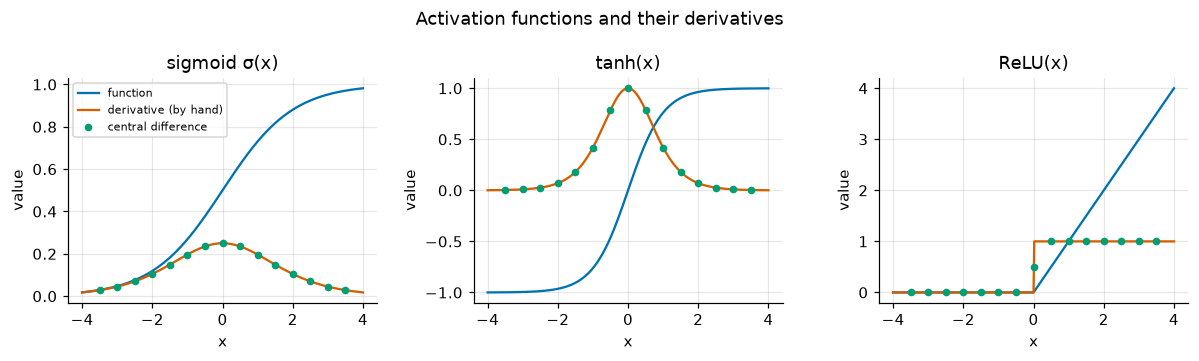

In [13]:
xs = torch.linspace(-4, 4, 401, dtype=f64)
dots = torch.linspace(-3.5, 3.5, 15, dtype=f64)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
panels = [("sigmoid σ(x)", torch.sigmoid, lambda t: torch.sigmoid(t) * (1 - torch.sigmoid(t))),
          ("tanh(x)", torch.tanh, lambda t: 1 - torch.tanh(t) ** 2),
          ("ReLU(x)", torch.relu, lambda t: (t > 0).to(f64))]
for ax, (name, f, df) in zip(axes, panels):
    ax.plot(xs, f(xs), color=COLORS[0], label="function")
    ax.plot(xs, df(xs), color=COLORS[1], label="derivative (by hand)")
    ax.plot(dots, derivative(f, dots), "o", color=COLORS[2], ms=4, label="central difference")
    ax.set_xlabel("x")
    ax.set_ylabel("value")
    ax.set_title(name)
axes[0].legend(fontsize=7)
fig.suptitle("Activation functions and their derivatives")
plt.tight_layout()
plt.show()

Notice that the sigmoid's slope is at most $0.25$ (the product $s(1-s)$ is largest at $s = 1/2$, i.e. at $x = 0$) and that both sigmoid and tanh become nearly flat for large $|x|$ — their derivatives almost vanish. Chapter 2 shows why that makes deep networks of these units hard to train. ReLU's derivative is exactly 1 for every positive input. One dot sits exactly at $x = 0$: the central difference there returns $0.5$, the average of the two one-sided slopes, as computed above. The vertical orange segment at $0$ is only the plotting program joining the two pieces; the derivative has no value there.

### Checkpoint 3.1

The **softplus** function $s(x) = \ln(1 + e^x)$ is a smooth version of ReLU. Derive $s'(x)$ by hand with the chain rule, then write `softplus_derivative(x)` that computes it elementwise for a tensor `x`. (Your answer simplifies to a function you met above.)

<details>
<summary><b>💡 Hint</b></summary>

Outer function $\ln u$ with derivative $1/u$; inner function $u = 1 + e^x$ with derivative $e^x$. Multiply: $\frac{e^x}{1 + e^x}$. Dividing top and bottom by $e^x$ shows it equals $\sigma(x)$.

</details>

In [ ]:
def softplus_derivative(x):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
xs_check = torch.linspace(-3, 3, 7, dtype=f64)
ours = softplus_derivative(xs_check)
check_shape(ours, (7,), "softplus_derivative(x)")
check_close(ours, derivative(lambda t: torch.log(1 + torch.exp(t)), xs_check), "softplus_derivative(x)", rtol=1e-7, atol=1e-8)
passed("Checkpoint 3.1")

## 4. Partial derivatives and the gradient

A loss depends on many parameters at once. Consider $f: \mathbb{R}^n \to \mathbb{R}$, a function taking a vector $\mathbf{x} = (x_1, \dots, x_n)$ to one number.

The **partial derivative** $\frac{\partial f}{\partial x_i}$ is the ordinary derivative with respect to $x_i$ while every other coordinate is held fixed. Collecting all $n$ of them gives the **gradient**, a vector of the same shape as $\mathbf{x}$:

$$\nabla f(\mathbf{x}) = \left(\frac{\partial f}{\partial x_1}, \dots, \frac{\partial f}{\partial x_n}\right).$$

**Example.** $f(\mathbf{x}) = x_1^2 + x_1 x_2 + 2 x_2^2$. Treating $x_2$ as a constant, $\frac{\partial f}{\partial x_1} = 2x_1 + x_2$. Treating $x_1$ as a constant, $\frac{\partial f}{\partial x_2} = x_1 + 4x_2$. At $\mathbf{x} = (1, 2)$: $\nabla f = (4, 9)$.

Numerically, partial derivative $i$ is a central difference that moves only coordinate $i$: perturb $\mathbf{x}$ by $\pm h \mathbf{e}_i$, where $\mathbf{e}_i$ is the vector with $1$ in position $i$ and $0$ elsewhere.

In [16]:
def f_bowl(x):  # x: (2,) → scalar
    return x[0] ** 2 + x[0] * x[1] + 2 * x[1] ** 2


def grad_f_bowl(x):  # by hand; (2,) → (2,)
    return torch.stack([2 * x[0] + x[1], x[0] + 4 * x[1]])


def fd_gradient(f, x, h=1e-6):
    """Central-difference gradient of a scalar function f at x (shape (n,), float64)."""
    grad = torch.zeros_like(x)
    for i in range(x.numel()):
        e = torch.zeros_like(x)
        e[i] = h
        grad[i] = (f(x + e) - f(x - e)) / (2 * h)
    return grad


p = torch.tensor([1.0, 2.0], dtype=f64)
print("gradient by hand:   ", grad_f_bowl(p))
print("finite differences: ", fd_gradient(f_bowl, p))

gradient by hand:    tensor([4., 9.], dtype=torch.float64)
finite differences:  tensor([4.0000, 9.0000], dtype=torch.float64)


### Directional derivatives

A partial derivative measures change along a coordinate axis. What about an arbitrary direction, given by a unit vector $\mathbf{u}$ ($\|\mathbf{u}\| = 1$)? The **directional derivative** is the rate of change of $f$ along the line $\mathbf{x} + t\mathbf{u}$:

$$D_{\mathbf{u}} f(\mathbf{x}) = \lim_{t \to 0} \frac{f(\mathbf{x} + t\mathbf{u}) - f(\mathbf{x})}{t}.$$

For a smooth $f$, small changes $\delta_i$ in the coordinates change $f$ by approximately the sum of their separate effects (stated without proof; this is the multivariable version of Taylor's first term):

$$f(\mathbf{x} + \boldsymbol{\delta}) \approx f(\mathbf{x}) + \sum_i \frac{\partial f}{\partial x_i} \delta_i = f(\mathbf{x}) + \nabla f(\mathbf{x}) \cdot \boldsymbol{\delta}.$$

With $\boldsymbol{\delta} = t\mathbf{u}$ this gives

$$D_{\mathbf{u}} f(\mathbf{x}) = \nabla f(\mathbf{x}) \cdot \mathbf{u}.$$

From notebook 02, $\nabla f \cdot \mathbf{u} = \|\nabla f\|\,\|\mathbf{u}\| \cos\theta = \|\nabla f\| \cos\theta$, where $\theta$ is the angle between $\mathbf{u}$ and the gradient. Two facts follow:

1. **The gradient points in the direction of steepest ascent.** $\cos\theta$ is largest, $1$, when $\mathbf{u}$ points along $\nabla f$; the rate of increase there is $\|\nabla f\|$. The opposite direction, $-\nabla f$, is the direction of steepest **descent**.
2. **The gradient is perpendicular to level sets.** A **level set** is a curve along which $f$ is constant (a contour line on a map). Moving along it, $f$ does not change, so the directional derivative along the curve is $0$, so $\cos\theta = 0$: the curve's direction is at $90°$ to $\nabla f$.

Check the formula $D_\mathbf{u} f = \nabla f \cdot \mathbf{u}$ for directions all around the circle at $\mathbf{x} = (1, 2)$:

max |finite difference − ∇f·u| over 73 directions: 1.2e-09


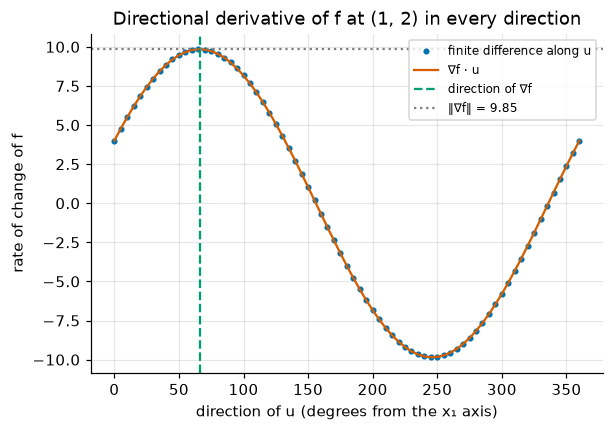

In [17]:
angles = torch.linspace(0, 2 * math.pi, 73, dtype=f64)
g = grad_f_bowl(p)
formula, numeric = [], []
for a in angles:
    u = torch.stack([torch.cos(a), torch.sin(a)])  # unit vector at angle a
    formula.append((g @ u).item())
    numeric.append(((f_bowl(p + 1e-6 * u) - f_bowl(p - 1e-6 * u)) / 2e-6).item())
print("max |finite difference − ∇f·u| over 73 directions:", f"{max(abs(a - b) for a, b in zip(formula, numeric)):.1e}")

grad_angle = math.atan2(g[1].item(), g[0].item())
plt.plot(torch.rad2deg(angles), numeric, "o", ms=3, label="finite difference along u")
plt.plot(torch.rad2deg(angles), formula, label="∇f · u")
plt.axvline(math.degrees(grad_angle), color=COLORS[2], ls="--", label="direction of ∇f")
plt.axhline(g.norm().item(), color="gray", ls=":", label=f"‖∇f‖ = {g.norm().item():.2f}")
plt.xlabel("direction of u (degrees from the x₁ axis)")
plt.ylabel("rate of change of f")
plt.title("Directional derivative of f at (1, 2) in every direction")
plt.legend(fontsize=8)
plt.show()

The rate of change follows a cosine: it peaks exactly in the gradient's direction (about 66°) at height $\|\nabla f\| = \sqrt{97} \approx 9.85$, is zero at right angles to the gradient, and is most negative in the opposite direction.

Now the picture on the plane. Arrows show the gradient direction at grid points (scaled to equal length so they stay readable — their real lengths vary).

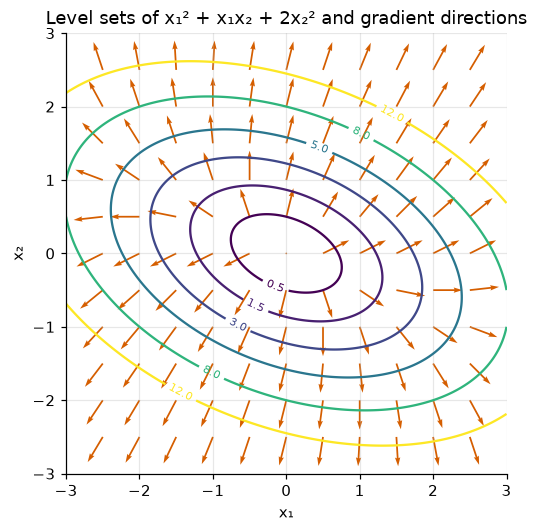

In [18]:
grid = torch.linspace(-3, 3, 201, dtype=f64)
X1, X2 = torch.meshgrid(grid, grid, indexing="xy")
F = X1**2 + X1 * X2 + 2 * X2**2

coarse = torch.linspace(-2.5, 2.5, 11, dtype=f64)
C1, C2 = torch.meshgrid(coarse, coarse, indexing="xy")
G1, G2 = 2 * C1 + C2, C1 + 4 * C2
length = torch.sqrt(G1**2 + G2**2).clamp_min(1e-12)

fig, ax = plt.subplots(figsize=(5.2, 5.2))
contours = ax.contour(X1, X2, F, levels=[0.5, 1.5, 3, 5, 8, 12], cmap="viridis")
ax.clabel(contours, fontsize=7)
ax.quiver(C1, C2, G1 / length, G2 / length, angles="xy", scale_units="xy", scale=2.5, color=COLORS[1], width=0.004)
ax.set_aspect("equal")
ax.set_xlabel("x₁")
ax.set_ylabel("x₂")
ax.set_title("Level sets of x₁² + x₁x₂ + 2x₂² and gradient directions")
plt.show()

Every arrow crosses the contour lines at a right angle and points "uphill", toward larger values. (Equal axis scaling matters here: stretching one axis would make right angles look skewed.)

To verify the right angle numerically rather than by eye, we trace one level set. Every term of $f$ has degree 2, so $f(r\mathbf{d}) = r^2 f(\mathbf{d})$; the point in direction $\mathbf{d}$ with $f = c$ is at $r = \sqrt{c / f(\mathbf{d})}$. We take many such points, estimate the curve's direction from neighbouring points, and measure its angle with the gradient.

In [19]:
c = 3.0
phis = torch.linspace(0, 2 * math.pi, 2001, dtype=f64)
dirs = torch.stack([torch.cos(phis), torch.sin(phis)], dim=1)               # (2001, 2)
f_dirs = dirs[:, 0] ** 2 + dirs[:, 0] * dirs[:, 1] + 2 * dirs[:, 1] ** 2     # f at each unit direction
points = torch.sqrt(c / f_dirs)[:, None] * dirs                              # (2001, 2), all with f = 3
tangents = points[2:] - points[:-2]                                          # curve direction at points[1:-1]
grads = torch.stack([2 * points[1:-1, 0] + points[1:-1, 1], points[1:-1, 0] + 4 * points[1:-1, 1]], dim=1)
cosines = (tangents * grads).sum(dim=1) / (tangents.norm(dim=1) * grads.norm(dim=1))
print("f on the traced curve: min", f"{f_bowl(points.T).min().item():.12f}", " max", f"{f_bowl(points.T).max().item():.12f}")
print(f"largest |cos(angle between curve and gradient)|: {cosines.abs().max().item():.1e}")

f on the traced curve: min 3.000000000000  max 3.000000000000
largest |cos(angle between curve and gradient)|: 7.6e-06


The cosine of the angle is zero to within the error of estimating the curve's direction from neighbouring points: the gradient is perpendicular to the level set at all 1999 points checked.

### Checkpoint 4.1

For $f(x, y) = x^2 y + \sin y$, compute the gradient by hand and store its value at $(x, y) = (1, 2)$ as a `float64` tensor `grad_at_point` of shape `(2,)`. Use `math.cos` or `torch.cos` for any cosine.

<details>
<summary><b>💡 Hint</b></summary>

Holding $y$ fixed, $x^2 y$ is $y$ times $x^2$, and $\sin y$ is a constant. Holding $x$ fixed, $x^2 y$ is $x^2$ times $y$. The gradient is $(2xy,\; x^2 + \cos y)$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_shape(grad_at_point, (2,), "grad_at_point")
check_close(grad_at_point, fd_gradient(lambda v: v[0] ** 2 * v[1] + torch.sin(v[1]), torch.tensor([1.0, 2.0], dtype=f64)),
            "grad_at_point", rtol=1e-7, atol=1e-8)
passed("Checkpoint 4.1")

## 5. Gradient descent

We can now answer the motivating question's first half. To decrease a loss $L(\boldsymbol{\theta})$ of parameters $\boldsymbol{\theta}$, move against the gradient:

$$\boldsymbol{\theta} \leftarrow \boldsymbol{\theta} - \eta\, \nabla L(\boldsymbol{\theta}),$$

where the **learning rate** $\eta > 0$ sets the step size. Repeating this is **gradient descent**. Each parameter moves opposite to its own partial derivative, by an amount proportional to it.

Why it works, for small $\eta$: with $\boldsymbol{\delta} = -\eta\,\nabla L$, the first-order approximation from Section 4 gives

$$L(\boldsymbol{\theta} - \eta \nabla L) \approx L(\boldsymbol{\theta}) - \eta\, \|\nabla L\|^2,$$

a decrease whenever the gradient is nonzero. Check this prediction on the bowl from Section 4:

In [22]:
theta = torch.tensor([1.0, 2.0], dtype=f64)
g = grad_f_bowl(theta)
for eta in [1e-2, 1e-3, 1e-4]:
    actual = f_bowl(theta - eta * g) - f_bowl(theta)
    predicted = -eta * (g @ g)
    print(f"eta = {eta:.0e}: actual change {actual.item():+.6f}   predicted −η‖∇L‖² {predicted.item():+.6f}")

eta = 1e-02: actual change -0.948600   predicted −η‖∇L‖² -0.970000
eta = 1e-03: actual change -0.096786   predicted −η‖∇L‖² -0.097000
eta = 1e-04: actual change -0.009698   predicted −η‖∇L‖² -0.009700


The prediction becomes accurate as $\eta$ shrinks: the relative gap falls about tenfold each time, because the neglected terms are proportional to $\eta^2$. The approximation only holds *near* $\boldsymbol{\theta}$ — which is exactly why "how far" is the hard half of the question.

### How far? The 1D quadratic

The simplest loss with a minimum is $f(x) = \frac{a}{2} x^2$ with $a > 0$. Its derivative is $f'(x) = a x$, and its second derivative — the **curvature** — is $a$. One gradient-descent step is

$$x_{t+1} = x_t - \eta\, a\, x_t = (1 - \eta a)\, x_t, \qquad\text{so}\qquad x_t = (1 - \eta a)^t\, x_0.$$

Everything depends on the factor $r = 1 - \eta a$:

| $\eta$ | factor $r$ | behaviour |
| --- | --- | --- |
| $0 < \eta < 1/a$ | $0 < r < 1$ | shrinks steadily toward 0 |
| $\eta = 1/a$ | $r = 0$ | lands on the minimum in one step |
| $1/a < \eta < 2/a$ | $-1 < r < 0$ | overshoots, flips sign each step, still converges |
| $\eta = 2/a$ | $r = -1$ | bounces between $\pm x_0$ forever |
| $\eta > 2/a$ | $r < -1$ | each step overshoots by more: **diverges** |

So gradient descent converges if and only if $0 < \eta < 2/a$. **The safe step size is set by the curvature**: a sharply curved loss requires a small learning rate.

eta = 0.05  factor 1 − ηa = +0.80   x_25 = +3.778e-03   max gap to (1 − ηa)^t x0: 1e-16
eta = 0.2   factor 1 − ηa = +0.20   x_25 = +3.355e-18   max gap to (1 − ηa)^t x0: 2e-18
eta = 0.45  factor 1 − ηa = -0.80   x_25 = -3.778e-03   max gap to (1 − ηa)^t x0: 1e-16
eta = 0.55  factor 1 − ηa = -1.20   x_25 = -9.540e+01   max gap to (1 − ηa)^t x0: 3e-14


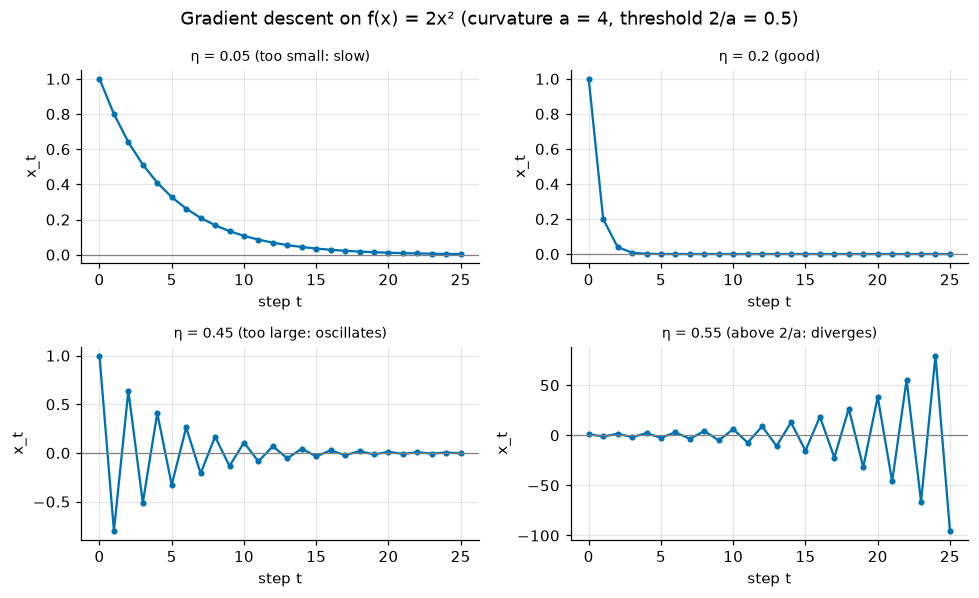

In [23]:
a, x0, steps = 4.0, 1.0, 25  # curvature a = 4, so the threshold is 2/a = 0.5
settings = [(0.05, "too small: slow"), (0.2, "good"), (0.45, "too large: oscillates"), (0.55, "above 2/a: diverges")]
fig, axes = plt.subplots(2, 2, figsize=(9, 5.5))
for ax, (eta, label) in zip(axes.flat, settings):
    x = x0
    trajectory = [x]
    for t in range(steps):
        x = x - eta * (a * x)  # gradient step with f'(x) = a x
        trajectory.append(x)
    closed_form = [(1 - eta * a) ** t * x0 for t in range(steps + 1)]
    gap = max(abs(u - v) for u, v in zip(trajectory, closed_form))
    print(f"eta = {eta:<5} factor 1 − ηa = {1 - eta * a:+.2f}   x_25 = {trajectory[-1]:+.3e}   max gap to (1 − ηa)^t x0: {gap:.0e}")
    ax.plot(trajectory, "o-", ms=3)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(f"η = {eta} ({label})", fontsize=9)
    ax.set_xlabel("step t")
    ax.set_ylabel("x_t")
fig.suptitle("Gradient descent on f(x) = 2x² (curvature a = 4, threshold 2/a = 0.5)")
plt.tight_layout()
plt.show()

The loops match the closed form $(1-\eta a)^t x_0$ up to rounding. With $\eta = 0.05$ the iterate creeps toward 0 (factor 0.8); with $\eta = 0.2$ it is essentially there after a few steps (factor 0.2); with $\eta = 0.45$ it zig-zags across the minimum but the zig-zags shrink (factor −0.8); with $\eta = 0.55$, just 10% above the threshold, it zig-zags outward and $|x_{25}|$ reaches about 95.

For a general smooth loss, the same analysis applies near a minimum with $a$ replaced by the local curvature $f''$ (stated without proof); far from the minimum it is only a guide.

### Two dimensions: different curvatures in different directions

Now take $f(\mathbf{x}) = \frac{1}{2}(\lambda_1 x_1^2 + \lambda_2 x_2^2)$ with $\lambda_1, \lambda_2 > 0$, a bowl with curvature $\lambda_1$ along $x_1$ and $\lambda_2$ along $x_2$. Its gradient is $(\lambda_1 x_1, \lambda_2 x_2)$, so gradient descent updates each coordinate separately, exactly as in 1D:

$$x_{1} \leftarrow (1 - \eta\lambda_1)\, x_1, \qquad x_{2} \leftarrow (1 - \eta\lambda_2)\, x_2.$$

One learning rate must serve both directions. Stability needs $\eta < 2/\lambda_{\max}$, the steepest direction's threshold. But then the flat direction shrinks by $1 - \eta\lambda_{\min}$ per step, which is close to 1 when $\lambda_{\min} \ll \lambda_{\max}$. The ratio

$$\kappa = \frac{\lambda_{\max}}{\lambda_{\min}}$$

is the **condition number**. A bowl with large $\kappa$ is **ill-conditioned**: long and narrow. We compare a round bowl, $\lambda = (1, 1)$, run with $\eta = 0.9$ (its limit is $2$), and a narrow bowl, $\lambda = (1, 20)$, run with $\eta = 0.09$ (its limit is $2/20 = 0.1$), and count steps until $\|\mathbf{x}\| < 10^{-3}\|\mathbf{x}_0\|$.

κ =    1, η = 0.900: factors per step +0.10 (x₁), +0.10 (x₂); steps to reach 1e-3: 3


κ =   20, η = 0.090: factors per step +0.91 (x₁), -0.80 (x₂); steps to reach 1e-3: 73


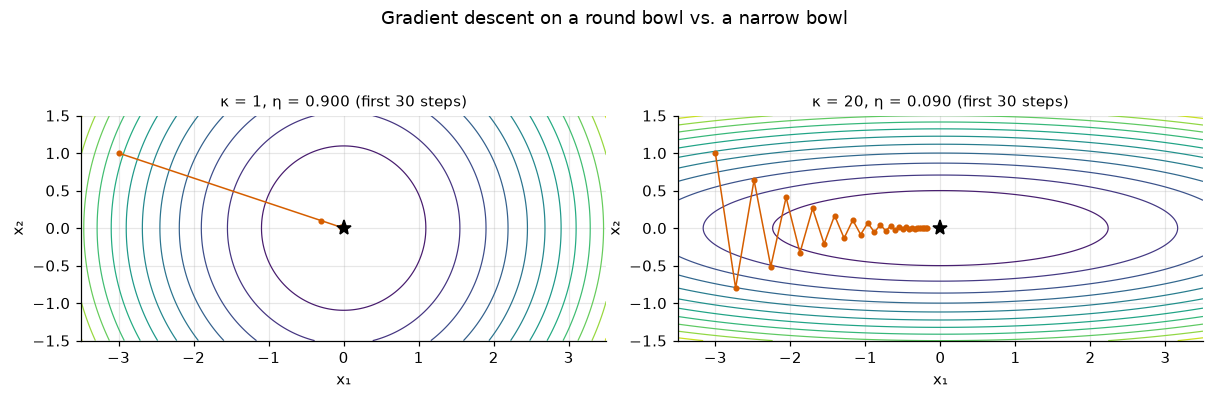

In [24]:
def run_quadratic_gd(lambdas, eta, x0, max_steps=1000, tol=1e-3):
    """Gradient descent on f(x) = ½ Σ λ_i x_i². Returns the trajectory (steps+1, 2) and steps to tolerance."""
    lam = torch.tensor(lambdas, dtype=f64)
    x = torch.tensor(x0, dtype=f64)
    path, reached = [x], None
    for t in range(1, max_steps + 1):
        x = x - eta * (lam * x)  # gradient of ½ Σ λ_i x_i² is (λ_1 x_1, λ_2 x_2)
        path.append(x)
        if reached is None and x.norm() < tol * path[0].norm():
            reached = t
    return torch.stack(path), reached


start = [-3.0, 1.0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (lambdas, eta) in zip(axes, [((1.0, 1.0), 0.9), ((1.0, 20.0), 0.09)]):
    path, reached = run_quadratic_gd(lambdas, eta, start)
    kappa = max(lambdas) / min(lambdas)
    print(f"κ = {kappa:>4.0f}, η = {eta:.3f}: factors per step {1 - eta * lambdas[0]:+.2f} (x₁), "
          f"{1 - eta * lambdas[1]:+.2f} (x₂); steps to reach 1e-3: {reached}")
    g1, g2 = torch.meshgrid(torch.linspace(-3.5, 3.5, 200, dtype=f64), torch.linspace(-1.5, 1.5, 200, dtype=f64), indexing="xy")
    ax.contour(g1, g2, 0.5 * (lambdas[0] * g1**2 + lambdas[1] * g2**2), levels=12, cmap="viridis", linewidths=0.8)
    shown = path[:31]
    ax.plot(shown[:, 0], shown[:, 1], "o-", color=COLORS[1], ms=3, lw=1)
    ax.plot([0], [0], "k*", ms=10)
    ax.set_aspect("equal")
    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")
    ax.set_title(f"κ = {kappa:.0f}, η = {eta:.3f} (first 30 steps)", fontsize=10)
fig.suptitle("Gradient descent on a round bowl vs. a narrow bowl")
plt.tight_layout()
plt.show()

On the round bowl ($\kappa = 1$) every direction has the same curvature, the learning rate can be large, and gradient descent heads straight for the minimum, shrinking the distance tenfold per step (factor 0.1): 3 steps. On the narrow bowl ($\kappa = 20$) the learning rate is limited by the steep $x_2$ direction, where the iterate zig-zags (factor −0.8), while along the flat $x_1$ direction it crawls (factor 0.91): 73 steps. The gradient points mostly across the valley, not along it.

Real losses have curvatures that differ by large factors, so this is a central obstacle in optimization. One cause is input features on very different scales; notebook 06 shows that **rescaling the features** makes the bowl rounder. Chapter 3 meets optimizers such as momentum and Adam that also reduce the problem. Exercise 4 measures how the number of steps grows with $\kappa$.

### Checkpoint 5.1

The loss $L(\boldsymbol{\theta}) = (\theta_1 - 3)^2 + 2(\theta_2 + 1)^2$ is at $\boldsymbol{\theta} = (0, 0)$. Compute its gradient there by hand, then take **one** gradient-descent step with $\eta = 0.1$. Store the gradient in `grad_L0` and the new parameters in `theta_1`, both as `float64` tensors of shape `(2,)`.

<details>
<summary><b>💡 Hint</b></summary>

$\partial L/\partial\theta_1 = 2(\theta_1 - 3)$ and $\partial L/\partial\theta_2 = 4(\theta_2 + 1)$, so the gradient at the origin is $(-6, 4)$. The step is $\boldsymbol{\theta} - 0.1 \times (-6, 4)$.

</details>

In [ ]:
theta_0 = torch.tensor([0.0, 0.0], dtype=f64)
eta = 0.1
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_shape(grad_L0, (2,), "grad_L0")
check_shape(theta_1, (2,), "theta_1")
check_close(grad_L0, fd_gradient(lambda t: (t[0] - 3) ** 2 + 2 * (t[1] + 1) ** 2, theta_0), "grad_L0", rtol=1e-7, atol=1e-8)
check_close(theta_1, torch.tensor([0.6, -0.4], dtype=f64), "theta_1")
passed("Checkpoint 5.1")

## 6. Vector-valued functions and the Jacobian

A layer of a neural network takes a vector in and gives a vector out. For $\mathbf{f}: \mathbb{R}^n \to \mathbb{R}^m$, each of the $m$ outputs $f_i$ has $n$ partial derivatives. Arrange them in an $m \times n$ matrix, the **Jacobian**:

$$J_{\mathbf{f}}(\mathbf{x}) = \begin{pmatrix} \frac{\partial f_1}{\partial x_1} & \cdots & \frac{\partial f_1}{\partial x_n} \\ \vdots & & \vdots \\ \frac{\partial f_m}{\partial x_1} & \cdots & \frac{\partial f_m}{\partial x_n} \end{pmatrix}, \qquad J_{ij} = \frac{\partial f_i}{\partial x_j}.$$

Row $i$ is the gradient of output $i$ (laid out as a row). Column $j$ says how all outputs respond to a nudge of input $j$ — so it can be estimated by a central difference along $\mathbf{e}_j$. The first-order approximation becomes a matrix–vector product: $\mathbf{f}(\mathbf{x} + \boldsymbol{\delta}) \approx \mathbf{f}(\mathbf{x}) + J_{\mathbf{f}}(\mathbf{x})\,\boldsymbol{\delta}$.

For a scalar function ($m = 1$) the Jacobian is a $1 \times n$ row; the gradient is the same numbers arranged as a vector of shape $(n,)$.

In [27]:
def fd_jacobian(f, x, h=1e-6):
    """Central-difference Jacobian of f: R^n → R^m at x (shape (n,), float64). Returns (m, n)."""
    columns = []
    for j in range(x.numel()):
        e = torch.zeros_like(x)
        e[j] = h
        columns.append((f(x + e) - f(x - e)) / (2 * h))  # column j: (m,)
    return torch.stack(columns, dim=1)

**Linear map.** For $\mathbf{f}(\mathbf{x}) = W\mathbf{x}$ with $W \in \mathbb{R}^{m \times n}$, output $i$ is $f_i = \sum_k W_{ik} x_k$, so $\partial f_i / \partial x_j = W_{ij}$. **The Jacobian of $\mathbf{x} \mapsto W\mathbf{x}$ is $W$ itself**, at every $\mathbf{x}$. Adding a constant vector $\mathbf{b}$ (an affine map $W\mathbf{x} + \mathbf{b}$, notebook 02) does not change it: constants have zero derivative.

In [28]:
gen = torch.Generator().manual_seed(0)
W = torch.randn(3, 4, generator=gen, dtype=f64)  # (m, n) = (3, 4)
b = torch.randn(3, generator=gen, dtype=f64)
x = torch.randn(4, generator=gen, dtype=f64)

J = fd_jacobian(lambda v: W @ v + b, x)
print("Jacobian shape:", tuple(J.shape), " (m, n) = (outputs, inputs)")
print("max |J − W| =", f"{(J - W).abs().max().item():.1e}")

Jacobian shape: (3, 4)  (m, n) = (outputs, inputs)
max |J − W| = 1.3e-10


**Elementwise functions.** For $\mathbf{f}(\mathbf{x}) = \tanh(\mathbf{x})$ applied to each entry, output $i$ depends only on input $i$. So $\partial f_i / \partial x_j = 0$ for $i \neq j$, and the Jacobian is **diagonal**, with $\tanh'(x_i) = 1 - \tanh^2(x_i)$ on the diagonal:

In [29]:
J_tanh = fd_jacobian(torch.tanh, x)
torch.set_printoptions(precision=4)
print(J_tanh)
print("diagonal by hand:", 1 - torch.tanh(x) ** 2)
print("off-diagonal entries exactly zero:", bool((J_tanh - torch.diag(torch.diagonal(J_tanh)) == 0).all()))
torch.set_printoptions(profile="default")

tensor([[0.9851, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.7372, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.8728, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.4925]], dtype=torch.float64)
diagonal by hand: tensor([0.9851, 0.7372, 0.8728, 0.4925], dtype=torch.float64)
off-diagonal entries exactly zero: True


Off the diagonal, nudging $x_j$ leaves $\tanh(x_i)$ bit-for-bit unchanged, so those finite differences are exactly zero. An $n$-dimensional elementwise function has an $n \times n$ Jacobian with only $n$ useful numbers in it — remember this for Section 8.

### Checkpoint 6.1

For $\mathbf{f}(x_1, x_2) = \big(x_1 x_2,\; x_1 + x_2^2,\; \sin x_1\big)$, write the $3 \times 2$ Jacobian by hand and store its value at $(1, 2)$ in `J_point`, a `float64` tensor.

<details>
<summary><b>💡 Hint</b></summary>

One row per output, one column per input. Row 1 is the gradient of $x_1 x_2$: $(x_2, x_1)$. Row 2: $(1, 2x_2)$. Row 3: $(\cos x_1, 0)$. Then plug in $x_1 = 1, x_2 = 2$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_shape(J_point, (3, 2), "J_point")
f_vec = lambda v: torch.stack([v[0] * v[1], v[0] + v[1] ** 2, torch.sin(v[0])])
check_close(J_point, fd_jacobian(f_vec, torch.tensor([1.0, 2.0], dtype=f64)), "J_point", rtol=1e-7, atol=1e-8)
passed("Checkpoint 6.1")

## 7. The chain rule as a product of Jacobians

Compose $\mathbf{f}: \mathbb{R}^n \to \mathbb{R}^k$ and $\mathbf{g}: \mathbb{R}^k \to \mathbb{R}^m$. Using the first-order approximation twice, as in the 1D chain rule:

$$\mathbf{g}(\mathbf{f}(\mathbf{x} + \boldsymbol{\delta})) \approx \mathbf{g}\big(\mathbf{f}(\mathbf{x}) + J_\mathbf{f}\boldsymbol{\delta}\big) \approx \mathbf{g}(\mathbf{f}(\mathbf{x})) + J_\mathbf{g}\, J_\mathbf{f}\, \boldsymbol{\delta}.$$

So the Jacobian of the composition is the **matrix product** of the Jacobians (we state the rigorous version without proof):

$$J_{\mathbf{g} \circ \mathbf{f}}(\mathbf{x}) = J_\mathbf{g}\big(\mathbf{f}(\mathbf{x})\big)\; J_\mathbf{f}(\mathbf{x}), \qquad (m \times n) = (m \times k)(k \times n).$$

The shapes chain like a matrix product must, and each Jacobian is evaluated at the point its own function receives. The 1D chain rule is the case $n = k = m = 1$.

**A tiny network.** Take $\mathbf{x} \in \mathbb{R}^3$ and compute

$$\mathbf{z} = W\mathbf{x} \;(W \in \mathbb{R}^{4\times 3}), \qquad \mathbf{h} = \tanh(\mathbf{z}), \qquad y = \mathbf{v} \cdot \mathbf{h} \;(\mathbf{v} \in \mathbb{R}^{4}).$$

The three Jacobians are $J_{\mathbf{z}} = W$ $(4\times 3)$; $J_{\mathbf{h}} = \mathrm{diag}(1 - \tanh^2(\mathbf{z}))$ $(4 \times 4)$; and $J_y = \mathbf{v}^\top$ $(1 \times 4)$, because $y = \sum_i v_i h_i$ has $\partial y / \partial h_i = v_i$. Their product is $1 \times 3$: the gradient of $y$ with respect to $\mathbf{x}$, as a row.

In [32]:
gen = torch.Generator().manual_seed(1)
W = torch.randn(4, 3, generator=gen, dtype=f64)
v = torch.randn(4, generator=gen, dtype=f64)
x = torch.randn(3, generator=gen, dtype=f64)


def tiny_net(x):  # (3,) → scalar
    return v @ torch.tanh(W @ x)


z = W @ x                                   # (4,)
J_z = W                                     # (4, 3)
J_h = torch.diag(1 - torch.tanh(z) ** 2)    # (4, 4), evaluated at z
J_y = v[None, :]                            # (1, 4)
chain = J_y @ J_h @ J_z                     # (1, 3)

print("chain-rule product:  ", chain.squeeze(0))
print("finite differences:  ", fd_gradient(tiny_net, x))
print("max |difference| for the inner Jacobian J_h J_z (4×3):",
      f"{(J_h @ J_z - fd_jacobian(lambda u: torch.tanh(W @ u), x)).abs().max().item():.1e}")

chain-rule product:   tensor([-0.7960,  0.2474,  0.1068], dtype=torch.float64)
finite differences:   tensor([-0.7960,  0.2474,  0.1068], dtype=torch.float64)
max |difference| for the inner Jacobian J_h J_z (4×3): 4.1e-11


Both the full gradient and the Jacobian of the first two stages agree with finite differences to about $10^{-10}$. Notice how little we had to think: write down each stage's Jacobian, multiply. This is how every gradient in deep learning is computed.

### Checkpoint 7.1

For $L(\mathbf{x}) = \frac{1}{2}\|W\mathbf{x} - \mathbf{t}\|^2$ with $W \in \mathbb{R}^{5 \times 3}$, use the chain rule with $\mathbf{r} = W\mathbf{x} - \mathbf{t}$ (Jacobian $W$) and $L = \frac{1}{2}\sum_i r_i^2$ (Jacobian $\mathbf{r}^\top$) to compute the gradient $\nabla_\mathbf{x} L$ as a tensor `grad_x` of shape `(3,)`.

<details>
<summary><b>💡 Hint</b></summary>

The product of Jacobians is $\mathbf{r}^\top W$, a $1 \times 3$ row. As a vector of shape `(3,)` that is $W^\top \mathbf{r}$, i.e. `W5.T @ r`. This is the gradient at the heart of linear regression (notebook 06), where we differentiate with respect to $W$ instead of $\mathbf{x}$.

</details>

In [ ]:
gen = torch.Generator().manual_seed(2)
W5 = torch.randn(5, 3, generator=gen, dtype=f64)
t5 = torch.randn(5, generator=gen, dtype=f64)
x3 = torch.randn(3, generator=gen, dtype=f64)
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_shape(grad_x, (3,), "grad_x")
check_close(grad_x, fd_gradient(lambda u: 0.5 * ((W5 @ u - t5) ** 2).sum(), x3), "grad_x", rtol=1e-7, atol=1e-8)
passed("Checkpoint 7.1")

## 8. Vector–Jacobian products: the efficient order

A network is a long chain $\mathbf{x} \to \mathbf{a}_1 \to \mathbf{a}_2 \to \dots \to \mathbf{a}_K \to L$ ending in a **scalar** loss. By Section 7 its gradient, as a row, is

$$\nabla L^\top = \underbrace{\mathbf{u}^\top}_{1 \times n} J_K\, J_{K-1} \cdots J_1,$$

where $\mathbf{u}^\top$ is the Jacobian of the final scalar step. Matrix multiplication is associative, so any order gives the same answer — but not the same **cost**. Suppose every $J_k$ is $n \times n$:

- **Right to left** (form $J_K \cdots J_1$ first): $K-1$ matrix–matrix products, each $n^3$ multiplications, then one vector–matrix product.
- **Left to right**: $\mathbf{u}^\top J_K$ is a row vector; multiply it by $J_{K-1}$, and so on. Every step is a **vector–Jacobian product (VJP)** costing $n^2$ multiplications, and no matrix–matrix product ever happens.

Starting at the scalar end keeps everything a vector. (Starting from the right with a single input direction is also cheap, but yields one directional derivative rather than the whole gradient; getting all $n$ partial derivatives that way needs $n$ passes.)

In [35]:
K = 10
print(f"Multiplications for a chain of K = {K} square n×n Jacobians")
print(f"{'n':>6} | {'right to left: (K−1)n³ + n²':>28} | {'left to right (VJPs): K n²':>27} | {'ratio':>6}")
for n in [10, 100, 1_000, 10_000]:
    mm = (K - 1) * n**3 + n**2
    vjp = K * n**2
    print(f"{n:>6,} | {mm:>28,} | {vjp:>27,} | {mm / vjp:>6,.0f}")

Multiplications for a chain of K = 10 square n×n Jacobians
     n |  right to left: (K−1)n³ + n² |  left to right (VJPs): K n² |  ratio
    10 |                        9,100 |                       1,000 |      9
   100 |                    9,010,000 |                     100,000 |     90
 1,000 |                9,001,000,000 |                  10,000,000 |    900
10,000 |            9,000,100,000,000 |               1,000,000,000 |  9,000


The ratio is about $n(K-1)/K$: VJPs are cheaper by roughly a factor of $n$, the layer width. Let's time both orders on a real chain and confirm they give the same gradient.

In [36]:
n, K = 1000, 5
gen = torch.Generator().manual_seed(3)
jacobians = [torch.randn(n, n, generator=gen, dtype=f64) / math.sqrt(n) for _ in range(K)]  # J_1 … J_K
u = torch.randn(n, generator=gen, dtype=f64)

start = time.perf_counter()
product = jacobians[0]
for J_k in jacobians[1:]:
    product = J_k @ product           # builds J_K ⋯ J_1, an (n, n) matrix
grad_right_to_left = u @ product
time_mm = time.perf_counter() - start

start = time.perf_counter()
row = u
for J_k in reversed(jacobians):
    row = row @ J_k                   # VJP: (n,) @ (n, n) → (n,)
grad_left_to_right = row
time_vjp = time.perf_counter() - start

print(f"right to left (matrix products): {time_mm * 1e3:8.2f} ms")
print(f"left to right (VJPs):            {time_vjp * 1e3:8.2f} ms   ({time_mm / time_vjp:.0f}× faster)")
print("same gradient:", torch.allclose(grad_right_to_left, grad_left_to_right),
      f" (max |difference| {(grad_right_to_left - grad_left_to_right).abs().max().item():.1e})")

right to left (matrix products):    14.95 ms
left to right (VJPs):                0.56 ms   (27× faster)
same gradient: True  (max |difference| 1.6e-14)


Both orders give the same gradient up to rounding, and the VJP order is much faster. The measured speed-up is smaller than the multiplication count suggests because matrix–matrix products run closer to the processor's peak speed than vector–matrix products do; exact timings depend on your machine.

### Elementwise Jacobians are never built

For an elementwise function such as $\tanh$, the Jacobian is $\mathrm{diag}(\mathbf{d})$ with $\mathbf{d} = \tanh'(\mathbf{z})$. Multiplying a row vector by a diagonal matrix just scales each entry:

$$\mathbf{w}^\top \mathrm{diag}(\mathbf{d}) = (w_1 d_1, \dots, w_n d_n) = (\mathbf{w} \odot \mathbf{d})^\top,$$

where $\odot$ is elementwise multiplication. That costs $n$ multiplications instead of $n^2$, and needs no $n \times n$ matrix. For a batch of 1,000 examples with 1,000 activations each — $n = 10^6$ numbers — the diagonal matrix would have $10^{12}$ entries, 4 terabytes in `float32`. So the Jacobian of an elementwise function is never materialised; its VJP is an elementwise product.

**This is exactly what autograd does.** PyTorch's `backward()` starts from the scalar loss and works backward through the computation — left to right in the product above — calling one VJP function per operation. Notebook 05 builds this up and lets you write your own VJP.

### Checkpoint 8.1

Given `z` and an upstream row vector `w` (both shape `(5,)`), compute the VJP of $\tanh$ at `z` — that is, $\mathbf{w}^\top J_{\tanh}(\mathbf{z})$ — **without** building a matrix. Store it in `vjp_tanh`, shape `(5,)`.

<details>
<summary><b>💡 Hint</b></summary>

The Jacobian is $\mathrm{diag}(1 - \tanh^2(\mathbf{z}))$, so the VJP is $\mathbf{w} \odot (1 - \tanh^2(\mathbf{z}))$: one elementwise multiplication.

</details>

In [ ]:
gen = torch.Generator().manual_seed(4)
z = torch.randn(5, generator=gen, dtype=f64)
w = torch.randn(5, generator=gen, dtype=f64)
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_shape(vjp_tanh, (5,), "vjp_tanh")
check_close(vjp_tanh, w @ fd_jacobian(torch.tanh, z), "vjp_tanh", rtol=1e-7, atol=1e-8)
passed("Checkpoint 8.1")

## Exercises

### Exercise 1 (modify): learning rate and curvature

The cell below runs 30 steps of gradient descent on $f(x) = \frac{a}{2}x^2$ from $x_0 = 1$. Run it with `a = 4.0` and each of `eta = 0.1`, `0.45`, `0.5`, `0.55`. Then set `a = 10.0` and run it with `eta = 0.25`. For each run, describe what happens (converges steadily, oscillates while converging, oscillates forever, diverges) and explain it with the factor $1 - \eta a$ and the threshold $2/a$.

<details>
<summary><b>💡 Hint</b></summary>

Before running, compute $1 - \eta a$ for each setting and predict the behaviour from the table in Section 5. $|x_{30}| = |1 - \eta a|^{30}$.

</details>

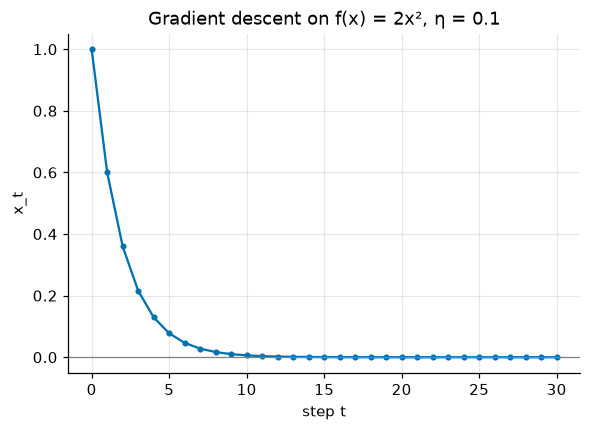

1 − ηa = +0.60, threshold 2/a = 0.50, |x_30| = 2.21e-07


In [39]:
a = 4.0      # curvature
eta = 0.1    # learning rate: try 0.1, 0.45, 0.5, 0.55; then a = 10.0 with eta = 0.25
x = 1.0
trajectory = [x]
for t in range(30):
    x = x - eta * a * x
    trajectory.append(x)

plt.plot(trajectory, "o-", ms=3)
plt.axhline(0, color="gray", lw=0.8)
plt.xlabel("step t")
plt.ylabel("x_t")
plt.title(f"Gradient descent on f(x) = {a / 2:g}x², η = {eta}")
plt.show()
print(f"1 − ηa = {1 - eta * a:+.2f}, threshold 2/a = {2 / a:.2f}, |x_30| = {abs(trajectory[-1]):.3g}")

*Your answer:*

### Exercise 2 (implement): numerical gradient and Jacobian checkers

Write two general-purpose checking tools — you will use them to test hand-derived gradients throughout the course:

- `numerical_gradient(f, x, h=1e-5)`: for $f: \mathbb{R}^n \to \mathbb{R}$ (returns a 0-dimensional tensor) and `x` of shape `(n,)`, return the central-difference gradient, shape `(n,)`.
- `numerical_jacobian(f, x, h=1e-5)`: for $\mathbf{f}: \mathbb{R}^n \to \mathbb{R}^m$ (returns shape `(m,)`), return the central-difference Jacobian, shape `(m, n)`.

Requirements: compute in `float64` even if `x` is `float32` (Section 2 showed why), return `float64` results, and **do not modify `x`** — a checker that changes its input silently corrupts the code it is checking. Try writing them without looking back at `fd_gradient` and `fd_jacobian`.

<details>
<summary><b>💡 Hint</b></summary>

Convert once with `x = x.detach().to(torch.float64)`. For each coordinate $j$, build a new tensor `e` that is zero except `e[j] = h`, and evaluate `f(x + e)` and `f(x - e)` — these create new tensors and leave `x` alone. Writing `x[j] += h` would modify the caller's tensor whenever it was already `float64` (`.to` returns the same tensor when no conversion is needed). For the Jacobian, collect the columns and combine them with `torch.stack(columns, dim=1)`.

</details>

In [ ]:
def numerical_gradient(f, x, h=1e-5):
    # YOUR CODE HERE
    raise NotImplementedError


def numerical_jacobian(f, x, h=1e-5):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
x_test = torch.tensor([0.5, -1.0, 2.0], dtype=f64)
x_saved = x_test.clone()


def f_test(x):  # f(x) = Σ x_i² + x_0 x_1, gradient 2x + (x_1, x_0, 0)
    return (x**2).sum() + x[0] * x[1]


grad_num = numerical_gradient(f_test, x_test)
grad_exact = 2 * x_test + torch.stack([x_test[1], x_test[0], torch.zeros((), dtype=f64)])
check_shape(grad_num, (3,), "numerical_gradient(f_test, x)")
check(grad_num.dtype == torch.float64, f"numerical_gradient should return float64, got {grad_num.dtype}")
check_close(grad_num, grad_exact, "numerical_gradient(f_test, x)", rtol=1e-8, atol=1e-8)
check(torch.equal(x_test, x_saved), "numerical_gradient modified its input x")
check_close(numerical_gradient(f_test, x_test.float()), grad_exact, "numerical_gradient on float32 input", rtol=1e-8, atol=1e-8)

gen = torch.Generator().manual_seed(5)
W_test = torch.randn(4, 3, generator=gen, dtype=f64)
b_test = torch.randn(4, generator=gen, dtype=f64)
layer = lambda x: torch.tanh(W_test @ x + b_test)               # R^3 → R^4
J_exact = torch.diag(1 - layer(x_test) ** 2) @ W_test            # (4, 3)
J_num = numerical_jacobian(layer, x_test)
check_shape(J_num, (4, 3), "numerical_jacobian(layer, x)")
check(J_num.dtype == torch.float64, f"numerical_jacobian should return float64, got {J_num.dtype}")
check_close(J_num, J_exact, "numerical_jacobian(layer, x)", rtol=1e-8, atol=1e-8)
check(torch.equal(x_test, x_saved), "numerical_jacobian modified its input x")
passed("Exercise 2")

### Exercise 3 (debug): a descent that climbs

`run_gradient_descent` should minimize $L(\boldsymbol{\theta}) = (\theta_1 - 1)^2 + 10(\theta_2 + 2)^2$, whose minimum is at $(1, -2)$. The buggy version (in the comments) instead runs off to large values. Find both bugs and write the fixed loop.

<details>
<summary><b>💡 Hint</b></summary>

Two separate problems: (1) which way does the update move relative to the gradient? (2) At which point is the gradient evaluated — and does that point change as the loop runs?

</details>

In [ ]:
def grad_L(theta):  # gradient of (θ1 − 1)² + 10(θ2 + 2)²
    return torch.stack([2 * (theta[0] - 1), 20 * (theta[1] + 2)])


def run_gradient_descent(grad_fn, theta0, eta, steps):
    # Buggy version:
    #     theta = theta0.clone()
    #     grad = grad_fn(theta)
    #     for step in range(steps):
    #         theta = theta + eta * grad
    #     return theta
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
theta_start = torch.zeros(2, dtype=f64)
theta_final = run_gradient_descent(grad_L, theta_start, eta=0.04, steps=300)
check_shape(theta_final, (2,), "run_gradient_descent(...)")
check_close(theta_final, torch.tensor([1.0, -2.0], dtype=f64), "θ after 300 steps", rtol=0, atol=1e-6)
check(torch.equal(theta_start, torch.zeros(2, dtype=f64)), "run_gradient_descent must not modify theta0")
passed("Exercise 3")

### Exercise 4 (investigate): how many steps does ill-conditioning cost?

Section 5 showed that a narrow bowl slows gradient descent. How does the number of steps grow with the condition number $\kappa$?

The scaffold runs gradient descent on $f(\mathbf{x}) = \frac{1}{2}\mathbf{x}^\top A\mathbf{x}$, a bowl with curvatures $\lambda_{\min} = 1$ and $\lambda_{\max} = \kappa$, rotated by 30° so its axes are not the coordinate axes. (Its gradient is $A\mathbf{x}$; we state this without proof — check it with your `numerical_gradient` if you like.) It uses the learning rate $\eta = 2/(\lambda_{\min} + \lambda_{\max})$ and counts the steps until $\|\mathbf{x}_t\| \le 10^{-6} \|\mathbf{x}_0\|$.

1. Run it and look at the table and the plot.
2. Explain why $\eta = 2/(\lambda_{\min} + \lambda_{\max})$ is the best fixed learning rate for this bowl. (Write $\mathbf{x}$ in the bowl's own rotated coordinates; each coordinate then behaves as in Section 5.)
3. Compare the measured steps with the theoretical rate: the error shrinks by the factor $\rho = \frac{\kappa - 1}{\kappa + 1}$ per step, so $\|\mathbf{x}_t\| = \rho^t \|\mathbf{x}_0\|$. How do the steps scale with $\kappa$? What does this mean for $\kappa = 10^4$?

<details>
<summary><b>💡 Hint</b></summary>

In the rotated coordinates the two coordinates are multiplied by $1 - \eta\lambda_{\min}$ and $1 - \eta\lambda_{\max}$ each step. The slower of the two decides the speed, so the best $\eta$ minimizes $\max(|1 - \eta\lambda_{\min}|, |1 - \eta\lambda_{\max}|)$. Where are the two equal? For large $\kappa$, use $\ln\frac{\kappa+1}{\kappa-1} \approx \frac{2}{\kappa}$.

</details>

    κ | measured steps |  from ρ^t ≤ tol | steps / κ
    1 |              1 |               1 |      1.00
    2 |             13 |              13 |      6.50
    5 |             35 |              35 |      7.00
   10 |             69 |              69 |      6.90
   20 |            139 |             139 |      6.95
   50 |            346 |             346 |      6.92
  100 |            691 |             691 |      6.91
  200 |           1382 |            1382 |      6.91


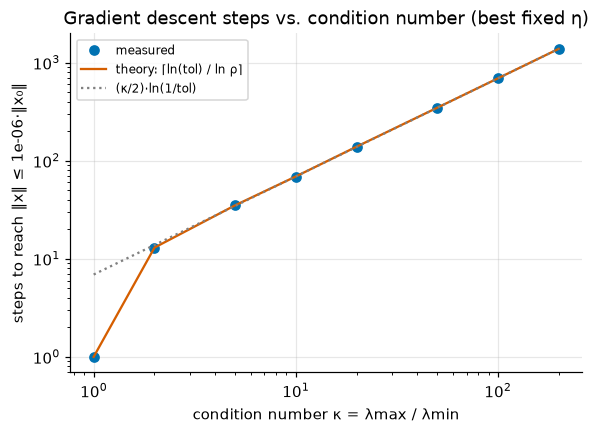

In [44]:
kappas = [1, 2, 5, 10, 20, 50, 100, 200]
tol = 1e-6
angle = math.radians(30)
R = torch.tensor([[math.cos(angle), -math.sin(angle)], [math.sin(angle), math.cos(angle)]], dtype=f64)

measured, predicted = [], []
for kappa in kappas:
    A = R @ torch.diag(torch.tensor([1.0, kappa], dtype=f64)) @ R.T  # curvatures 1 and κ, rotated 30°
    eta = 2 / (1 + kappa)
    x = torch.tensor([1.0, 1.0], dtype=f64)
    x0_norm = x.norm()
    steps = 0
    while x.norm() > tol * x0_norm:
        x = x - eta * (A @ x)
        steps += 1
    measured.append(steps)
    rho = (kappa - 1) / (kappa + 1)
    predicted.append(1 if rho == 0 else math.ceil(math.log(tol) / math.log(rho)))

print(f"{'κ':>5} | {'measured steps':>14} | {'from ρ^t ≤ tol':>15} | {'steps / κ':>9}")
for kappa, m, p in zip(kappas, measured, predicted):
    print(f"{kappa:>5} | {m:>14} | {p:>15} | {m / kappa:>9.2f}")

ks = torch.tensor(kappas, dtype=f64)
plt.loglog(kappas, measured, "o", ms=6, label="measured")
plt.loglog(kappas, predicted, "-", label="theory: ⌈ln(tol) / ln ρ⌉")
plt.loglog(kappas, (ks / 2 * math.log(1 / tol)).tolist(), ":", color="gray", label="(κ/2)·ln(1/tol)")
plt.xlabel("condition number κ = λmax / λmin")
plt.ylabel(f"steps to reach ‖x‖ ≤ {tol:g}·‖x₀‖")
plt.title("Gradient descent steps vs. condition number (best fixed η)")
plt.legend(fontsize=8)
plt.show()

*Your conclusion:*

## Summary and what's next

- The **derivative** is the limit of secant slopes: the rate at which a function changes. **Finite differences** approximate it; the central difference has error $O(h^2)$, but rounding error grows like $\varepsilon/h$, so there is a best $h$ and a floor on accuracy. Use finite differences in `float64` as a **check**, never to train.
- The **power, sum, product, and chain rules** give exact derivatives, including $\sigma' = \sigma(1 - \sigma)$ and $\tanh' = 1 - \tanh^2$. ReLU has no derivative at 0; frameworks use 0.
- The **gradient** collects partial derivatives. It points in the direction of steepest ascent, is perpendicular to level sets, and gives every directional derivative as $\nabla f \cdot \mathbf{u}$.
- **Gradient descent**, $\boldsymbol{\theta} \leftarrow \boldsymbol{\theta} - \eta\nabla L$, answers "which direction". "How far" is limited by curvature: on a quadratic, $\eta < 2/\lambda_{\max}$ is required, and an ill-conditioned loss needs a number of steps proportional to $\kappa$.
- The **Jacobian** of $\mathbf{f}: \mathbb{R}^n \to \mathbb{R}^m$ is $m \times n$; for $W\mathbf{x}$ it is $W$, for elementwise functions it is diagonal. The **chain rule** multiplies Jacobians, and for a scalar loss the cheap order is left to right: a sequence of **vector–Jacobian products**, with elementwise Jacobians applied as elementwise products.

We now know how to *minimize* a loss once we have one. But which loss should we minimize? Why squared error for some problems and something else for classification? Notebook 04 answers this from probability: a good loss is the negative log-likelihood of the data under a model, and that idea produces mean squared error, cross-entropy, and more.